<a href="https://colab.research.google.com/github/ReztriLestari/Taxis-Dataset---ML/blob/main/visualisasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ============================================================
# SEL 1: IMPORT LIBRARY
# ============================================================

# Pandas digunakan untuk membaca dan mengolah dataset
# dalam bentuk tabel atau DataFrame.
import pandas as pd

# NumPy digunakan untuk operasi numerik.
import numpy as np

# Matplotlib digunakan untuk mengatur dan menampilkan grafik.
import matplotlib.pyplot as plt

# Seaborn digunakan untuk membuat visualisasi statistik.
import seaborn as sns

# Mengatur tampilan visualisasi agar konsisten.
sns.set_theme(style="whitegrid", palette="deep")

# Mengatur ukuran dan resolusi grafik secara default.
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 120

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


In [3]:
# ============================================================
# SEL 2: MEMBACA DATASET TAXIS
# ============================================================

# Membaca file CSV menggunakan Pandas.
# File harus berada dalam folder kerja yang sama.
df = pd.read_csv("/content/sample_data/taxis.csv")

# Menampilkan lima baris pertama dataset.
print("Lima baris pertama dataset:")
display(df.head())

# Menampilkan jumlah baris dan kolom.
print("\nUkuran dataset:", df.shape)

# Menampilkan nama seluruh kolom.
print("\nDaftar kolom:")
print(df.columns.tolist())

Lima baris pertama dataset:


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan



Ukuran dataset: (6433, 14)

Daftar kolom:
['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls', 'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']


In [4]:
# ============================================================
# SEL 3: EKSPLORASI STRUKTUR DATA
# ============================================================

# Menampilkan informasi umum dataset.
print("Informasi Dataset:")
df.info()

# Menampilkan tipe data setiap kolom.
print("\nTipe Data Setiap Variabel:")
print(df.dtypes)

# Menampilkan jumlah nilai unik setiap kolom.
print("\nJumlah Nilai Unik:")
print(df.nunique())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pickup           6433 non-null   object 
 1   dropoff          6433 non-null   object 
 2   passengers       6433 non-null   int64  
 3   distance         6433 non-null   float64
 4   fare             6433 non-null   float64
 5   tip              6433 non-null   float64
 6   tolls            6433 non-null   float64
 7   total            6433 non-null   float64
 8   color            6433 non-null   object 
 9   payment          6389 non-null   object 
 10  pickup_zone      6407 non-null   object 
 11  dropoff_zone     6388 non-null   object 
 12  pickup_borough   6407 non-null   object 
 13  dropoff_borough  6388 non-null   object 
dtypes: float64(5), int64(1), object(8)
memory usage: 703.7+ KB

Tipe Data Setiap Variabel:
pickup              object
dropoff            

In [5]:
# ============================================================
# SEL 4: IDENTIFIKASI MISSING VALUES
# ============================================================

# Menghitung jumlah missing values setiap kolom.
missing = df.isnull().sum()

# Menghitung persentase missing values setiap kolom.
persentase = (missing / len(df)) * 100

# Membuat tabel ringkasan missing values.
tabel_missing = pd.DataFrame({
    "Jumlah Missing": missing,
    "Persentase (%)": persentase.round(2)
})

# Mengurutkan berdasarkan jumlah missing terbesar.
tabel_missing = tabel_missing.sort_values(
    by="Jumlah Missing",
    ascending=False
)

# Menampilkan tabel.
display(tabel_missing)

# Menghitung total missing values.
print("Total sel kosong:", missing.sum())

# Menghitung jumlah baris yang memiliki minimal satu nilai kosong.
print(
    "Jumlah baris dengan missing values:",
    df.isnull().any(axis=1).sum()
)

,Jumlah Missing,Persentase (%)
dropoff_zone,45,0.70
dropoff_borough,45,0.70
payment,44,0.68
pickup_zone,26,0.40
pickup_borough,26,0.40
pickup,0,0.00
tip,0,0.00
fare,0,0.00
distance,0,0.00
passengers,0,0.00


Total sel kosong: 186
Jumlah baris dengan missing values: 92


In [6]:
# ============================================================
# SEL 5: STATISTIK DESKRIPTIF
# ============================================================

# Menampilkan statistik variabel numerik.
statistik = df.describe()

display(statistik.round(2))

# Menampilkan jumlah data setiap wilayah penjemputan.
print("\nJumlah perjalanan berdasarkan wilayah:")

display(
    df["pickup_borough"].value_counts(
        dropna=False
    )
)

,passengers,distance,fare,tip,tolls,total
count,6433.00,6433.00,6433.00,6433.00,6433.00,6433.00
mean,1.54,3.02,13.09,1.98,0.33,18.52
std,1.20,3.83,11.55,2.45,1.42,13.82
min,0.00,0.00,1.00,0.00,0.00,1.30
25%,1.00,0.98,6.50,0.00,0.00,10.80
50%,1.00,1.64,9.50,1.70,0.00,14.16
75%,2.00,3.21,15.00,2.80,0.00,20.30
max,6.00,36.70,150.00,33.20,24.02,174.82



Jumlah perjalanan berdasarkan wilayah:


,count
pickup_borough,
Manhattan,5268
Queens,657
Brooklyn,383
Bronx,99
NaN,26


In [7]:
# ============================================================
# SEL 6: DATA PREPROCESSING
# ============================================================

# Membuat salinan dataset asli.
# Dengan cara ini, data asli tidak berubah.
data = df.copy()

# Mengubah kolom pickup dan dropoff menjadi datetime.
data["pickup"] = pd.to_datetime(
    data["pickup"], errors="coerce"
)

data["dropoff"] = pd.to_datetime(
    data["dropoff"], errors="coerce"
)

# Menghitung durasi perjalanan dalam menit.
# total_seconds() menghasilkan selisih waktu dalam detik.
# Dibagi 60 untuk mengubahnya menjadi menit.
data["duration_min"] = (
    data["dropoff"] - data["pickup"]
).dt.total_seconds() / 60

# Memeriksa jumlah durasi yang tidak valid.
# Durasi nol atau negatif tidak digunakan dalam analisis durasi.
durasi_tidak_valid = (
    (data["duration_min"] <= 0) |
    (data["duration_min"].isna())
)

print(
    "Jumlah durasi tidak valid:",
    durasi_tidak_valid.sum()
)

# Mengganti durasi yang tidak valid menjadi NaN.
# Data perjalanan tetap dipertahankan untuk analisis lain.
data.loc[durasi_tidak_valid, "duration_min"] = np.nan

# Menampilkan hasil perhitungan durasi.
display(
    data[["pickup", "dropoff", "duration_min"]].head()
)

print("\nJumlah data setelah persiapan:", len(data))

Jumlah durasi tidak valid: 6


,pickup,dropoff,duration_min
0,2019-03-23 20:21:09,2019-03-23 20:27:24,6.250000
1,2019-03-04 16:11:55,2019-03-04 16:19:00,7.083333
2,2019-03-27 17:53:01,2019-03-27 18:00:25,7.400000
3,2019-03-10 01:23:59,2019-03-10 01:49:51,25.866667
4,2019-03-30 13:27:42,2019-03-30 13:37:14,9.533333



Jumlah data setelah persiapan: 6433


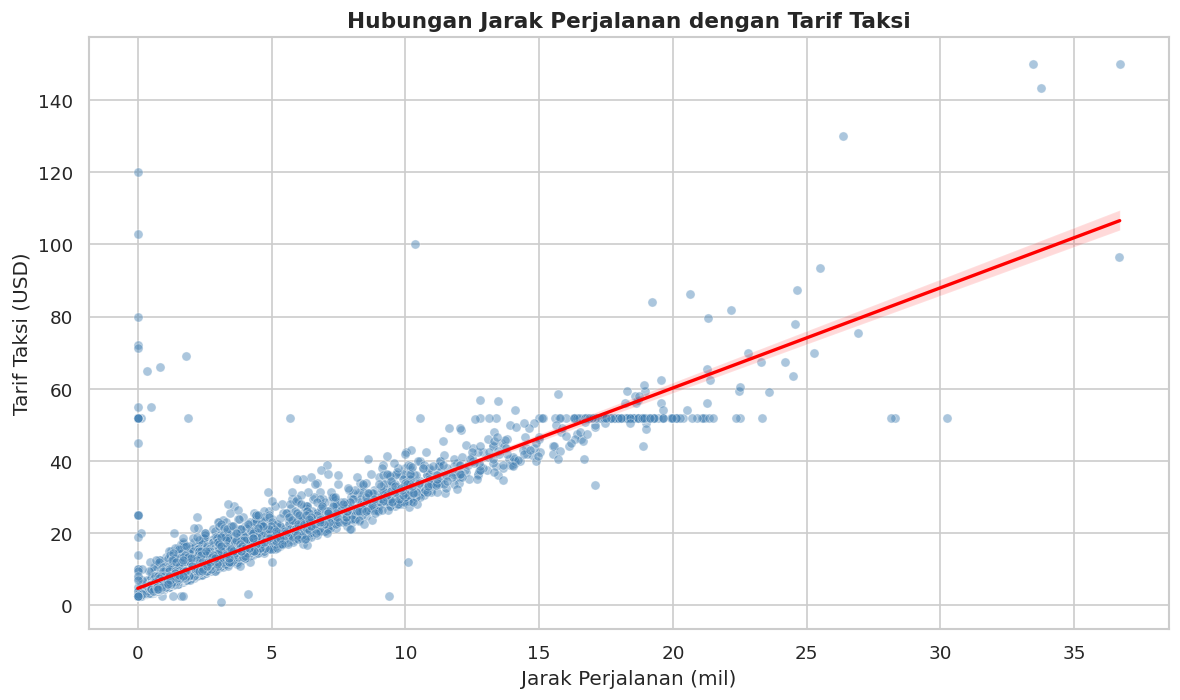

Korelasi Pearson jarak dan tarif: 0.920


In [8]:
# ============================================================
# SEL 7: SCATTER PLOT
# HUBUNGAN JARAK PERJALANAN DAN TARIF TAKSI
# ============================================================

# Mengambil data yang memiliki nilai distance dan fare.
data_scatter = data.dropna(
    subset=["distance", "fare"]
)

# Membuat area grafik.
plt.figure(figsize=(10, 6))

# Membuat scatter plot.
sns.scatterplot(
    data=data_scatter,
    x="distance",
    y="fare",
    alpha=0.45,
    color="steelblue",
    s=30
)

# Menambahkan garis regresi linear.
sns.regplot(
    data=data_scatter,
    x="distance",
    y="fare",
    scatter=False,
    color="red",
    line_kws={"linewidth": 2}
)

# Menambahkan judul dan label sumbu.
plt.title(
    "Hubungan Jarak Perjalanan dengan Tarif Taksi",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Jarak Perjalanan (mil)")
plt.ylabel("Tarif Taksi (USD)")

# Mengatur tata letak grafik.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

# Menghitung korelasi Pearson.
korelasi_jarak = data_scatter[
    ["distance", "fare"]
].corr().loc["distance", "fare"]

print(
    f"Korelasi Pearson jarak dan tarif: {korelasi_jarak:.3f}"
)

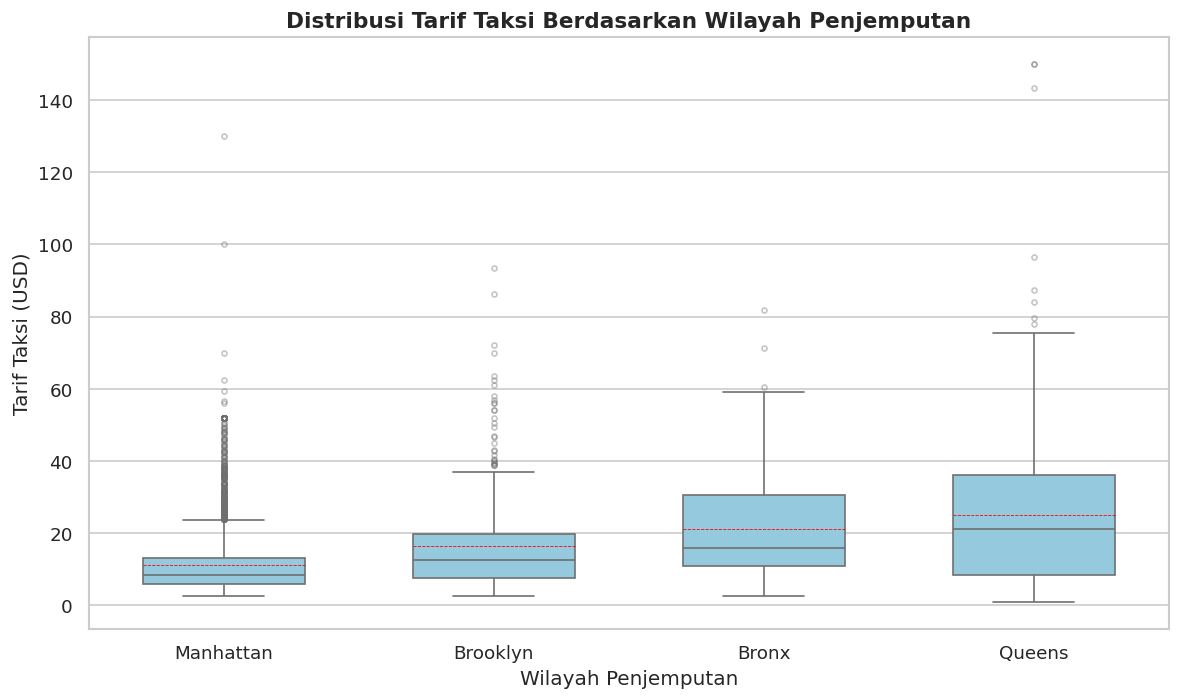

,jumlah,rata_rata,median,minimum,maksimum
pickup_borough,,,,,
Bronx,99,21.00,16.0,2.5,81.86
Brooklyn,383,16.52,12.5,2.5,93.50
Manhattan,5268,11.15,8.5,2.5,130.00
Queens,657,24.93,21.0,1.0,150.00


In [9]:
# ============================================================
# SEL 8: BOX PLOT
# DISTRIBUSI TARIF BERDASARKAN WILAYAH
# ============================================================

# Menghapus nilai kosong hanya pada variabel yang digunakan.
data_boxplot = data.dropna(
    subset=["pickup_borough", "fare"]
)

# Mengurutkan wilayah berdasarkan median tarif.
urutan_wilayah = (
    data_boxplot
    .groupby("pickup_borough")["fare"]
    .median()
    .sort_values()
    .index
)

# Membuat area grafik.
plt.figure(figsize=(10, 6))

# Membuat box plot.
sns.boxplot(
    data=data_boxplot,
    x="pickup_borough",
    y="fare",
    order=urutan_wilayah,
    color="skyblue",
    width=0.6,
    showmeans=True,  # <-- INI KODE UTAMA UNTUK MENAMPILKAN RATA-RATA
    meanline=True,  # <-- MENGUBAH SIMBOL MENJADI GARIS HORIZONTAL
    meanprops={  # Mengatur gaya garis putus-putus
        "color": "red",  # Warna garis (bisa diganti 'black' atau 'darkblue')
        "linestyle": "--",  # <-- GAYA GARIS PUTUS-PUTUS (dashed)
        "linewidth": 0.5,  # Ketebalan garis
    },
    flierprops={
        "marker": "o",
        "markersize": 3,
        "alpha": 0.4
    }
)

# Memberikan judul dan label.
plt.title(
    "Distribusi Tarif Taksi Berdasarkan Wilayah Penjemputan",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Wilayah Penjemputan")
plt.ylabel("Tarif Taksi (USD)")

plt.tight_layout()
plt.show()

# Menghitung statistik tarif tiap wilayah.
statistik_wilayah = (
    data_boxplot
    .groupby("pickup_borough")["fare"]
    .agg(
        jumlah="count",
        rata_rata="mean",
        median="median",
        minimum="min",
        maksimum="max"
    )
    .round(2)
)

display(statistik_wilayah)

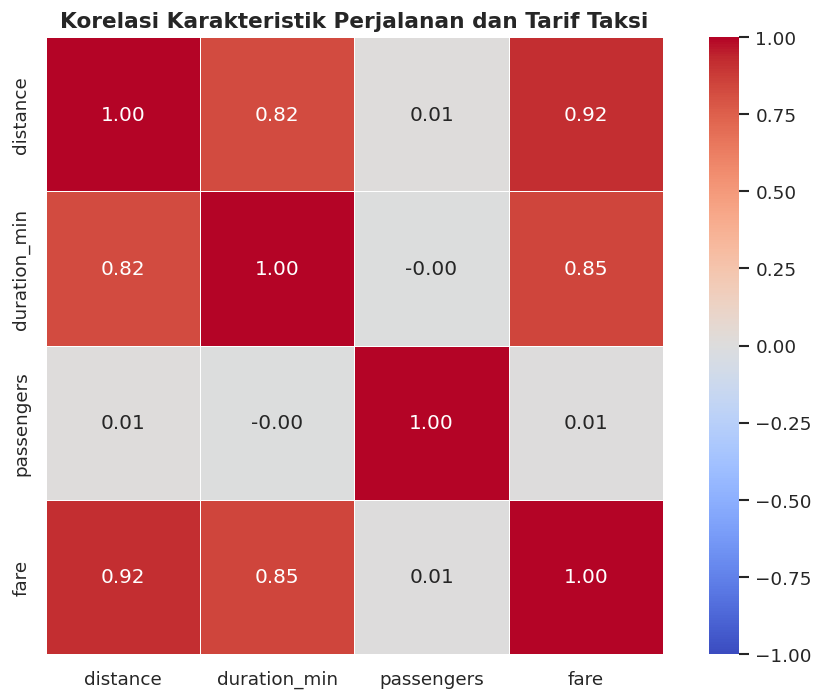

Korelasi variabel terhadap tarif:


,fare
distance,0.920
duration_min,0.851
passengers,0.008


In [10]:
# ============================================================
# SEL 9: HEATMAP KORELASI
# ============================================================

# Memilih variabel numerik yang ingin dibandingkan.
variabel = [
    "distance",
    "duration_min",
    "passengers",
    "fare"
]

# Membuat dataset khusus analisis korelasi.
data_korelasi = data[variabel].copy()

# Menghitung matriks korelasi Pearson.
# Secara default, Pandas menggunakan pasangan data valid
# pada setiap perhitungan korelasi.
matriks_korelasi = data_korelasi.corr(
    method="pearson"
)

# Membuat area grafik.
plt.figure(figsize=(8, 6))

# Membuat heatmap.
sns.heatmap(
    matriks_korelasi,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)

# Memberikan judul grafik.
plt.title(
    "Korelasi Karakteristik Perjalanan dan Tarif Taksi",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Mengurutkan korelasi setiap fitur terhadap tarif.
korelasi_tarif = (
    matriks_korelasi["fare"]
    .drop("fare")
    .sort_values(ascending=False)
)

print("Korelasi variabel terhadap tarif:")
display(korelasi_tarif.round(3))

In [11]:
# ============================================================
# SEL 10: RINGKASAN HASIL ANALISIS
# ============================================================

print("=" * 55)
print("RINGKASAN ANALISIS VISUALISASI TAXIS")
print("=" * 55)

# 1. Hubungan jarak dan tarif.
print("\n1. HUBUNGAN JARAK DAN TARIF")
print(f"Korelasi Pearson: {korelasi_jarak:.3f}")

# 2. Perbandingan tarif berdasarkan wilayah.
print("\n2. TARIF BERDASARKAN WILAYAH")

median_wilayah = (
    data_boxplot
    .groupby("pickup_borough")["fare"]
    .median()
    .sort_values(ascending=False)
)

display(median_wilayah.round(2))

# 3. Korelasi karakteristik perjalanan.
print("\n3. KORELASI TERHADAP TARIF")

display(korelasi_tarif.round(3))

# 4. Ringkasan jumlah observasi.
print("\n4. JUMLAH OBSERVASI")
print("Dataset asli:", len(df))
print("Scatter Plot:", len(data_scatter))
print("Box Plot:", len(data_boxplot))
print("Heatmap: menggunakan pasangan observasi valid")

RINGKASAN ANALISIS VISUALISASI TAXIS

1. HUBUNGAN JARAK DAN TARIF
Korelasi Pearson: 0.920

2. TARIF BERDASARKAN WILAYAH


,fare
pickup_borough,
Queens,21.0
Bronx,16.0
Brooklyn,12.5
Manhattan,8.5



3. KORELASI TERHADAP TARIF


,fare
distance,0.920
duration_min,0.851
passengers,0.008



4. JUMLAH OBSERVASI
Dataset asli: 6433
Scatter Plot: 6433
Box Plot: 6407
Heatmap: menggunakan pasangan observasi valid


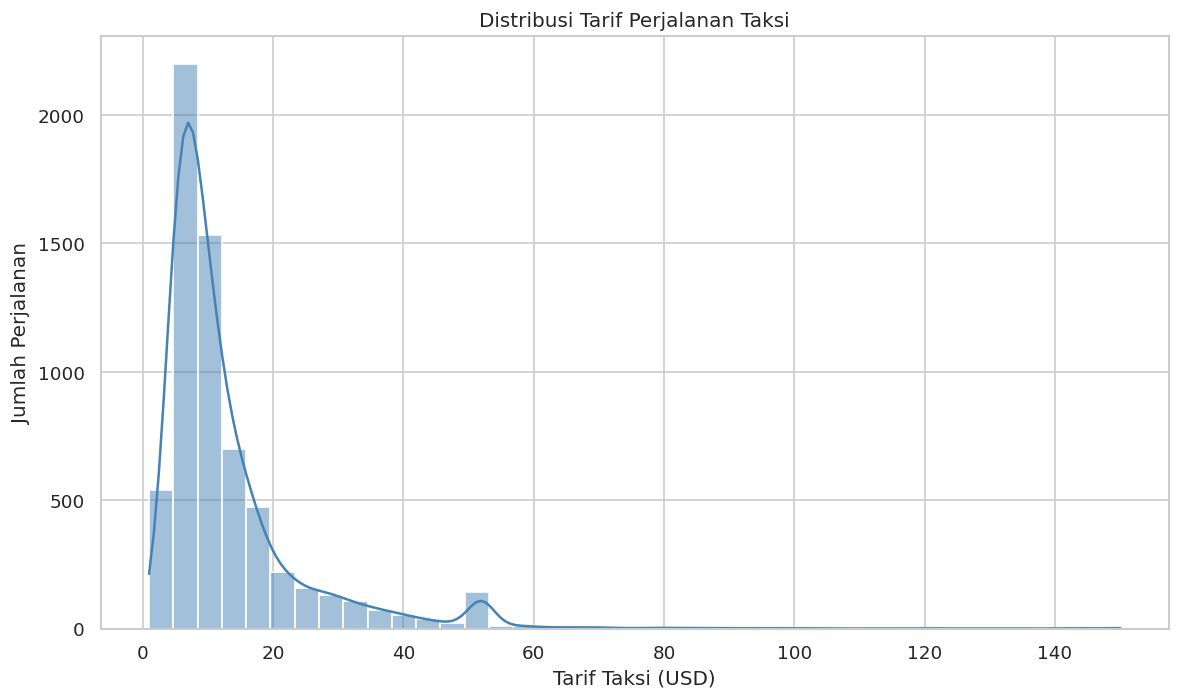

In [12]:
# =================================================
# VISUALISASI TAMBAHAN: HISTOGRAM TARIF
# =================================================

import seaborn as sns
import matplotlib.pyplot as plt

# Membaca dataset langsung dari repository resmi
# agar dapat dijalankan melalui Google Colab.
import pandas as pd

df = pd.read_csv(
    "https://raw.githubusercontent.com/"
    "mwaskom/seaborn-data/master/taxis.csv"
)

# Membuat histogram distribusi tarif.
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="fare",
    bins=40,
    kde=True,
    color="steelblue"
)

plt.title("Distribusi Tarif Perjalanan Taksi")
plt.xlabel("Tarif Taksi (USD)")
plt.ylabel("Jumlah Perjalanan")

plt.tight_layout()
plt.show()

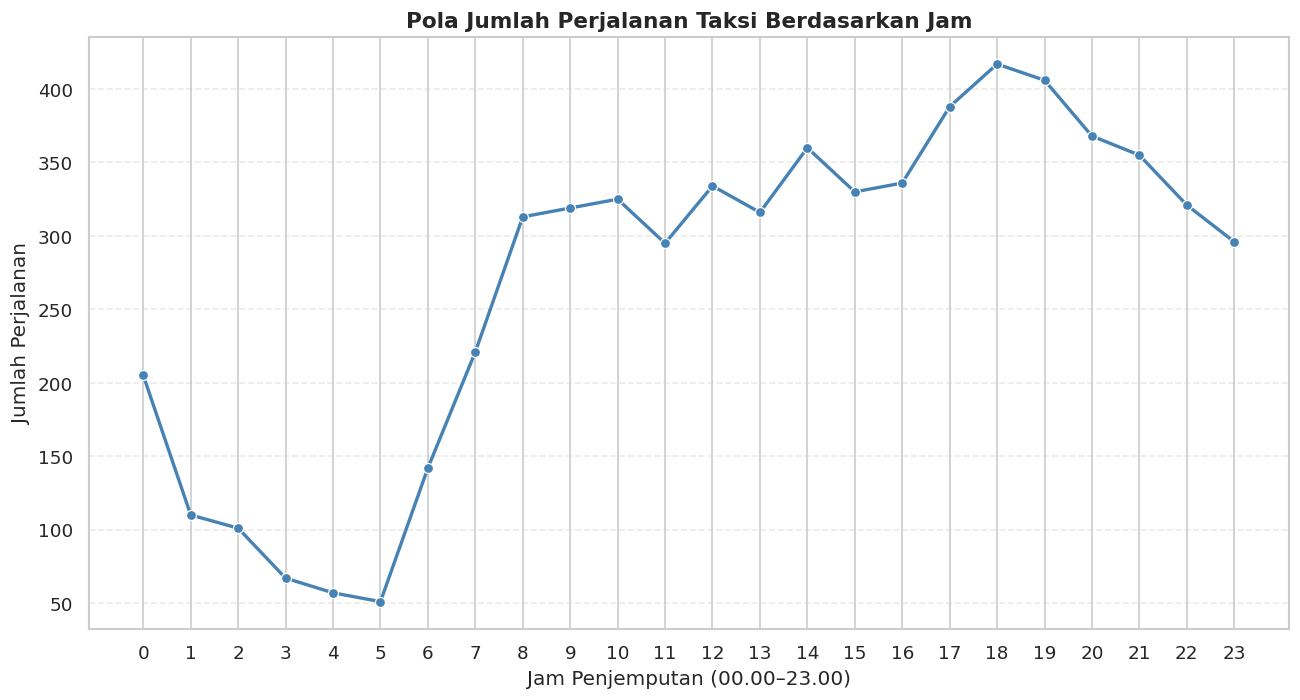

HASIL ANALISIS POLA PERJALANAN
---------------------------------------------
Jam paling ramai: 18.00 (417 perjalanan)
Jam paling sepi: 05.00 (51 perjalanan)


,Jam,Jumlah Perjalanan
0,0,205
1,1,110
2,2,101
3,3,67
4,4,57
5,5,51
6,6,142
7,7,221
8,8,313
9,9,319


In [13]:
# ============================================================
# SEL 11: LINE CHART
# POLA JUMLAH PERJALANAN BERDASARKAN JAM PENJEMPUTAN
# ============================================================

# Membuat salinan data untuk analisis waktu.
# Tujuannya agar data utama tidak mengalami perubahan.
data_waktu = data.copy()

# Mengambil jam dari kolom pickup.
# dt.hour menghasilkan angka 0 sampai 23.
# Contoh: 14:35:20 akan menghasilkan angka 14.
data_waktu["jam_pickup"] = data_waktu["pickup"].dt.hour

# Menghitung jumlah perjalanan untuk setiap jam.
# value_counts() menghitung banyaknya kemunculan jam.
# sort_index() mengurutkan jam dari 0 sampai 23.
jumlah_per_jam = (
    data_waktu["jam_pickup"]
    .value_counts()
    .sort_index()
)

# Memastikan seluruh jam 0 sampai 23 ditampilkan.
# Jam yang tidak memiliki perjalanan akan bernilai 0.
jumlah_per_jam = jumlah_per_jam.reindex(
    range(24),
    fill_value=0
)

# Membuat area grafik.
plt.figure(figsize=(11, 6))

# Membuat grafik garis.
sns.lineplot(
    x=jumlah_per_jam.index,
    y=jumlah_per_jam.values,
    marker="o",
    color="steelblue",
    linewidth=2,
    markersize=6
)

# Memberikan judul dan label sumbu.
plt.title(
    "Pola Jumlah Perjalanan Taksi Berdasarkan Jam",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Jam Penjemputan (00.00–23.00)")
plt.ylabel("Jumlah Perjalanan")

# Menampilkan seluruh jam pada sumbu X.
plt.xticks(range(24))

# Menampilkan garis bantu horizontal.
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# ============================================================
# ANALISIS STATISTIK
# ============================================================

# Menentukan jam dengan jumlah perjalanan terbanyak.
jam_tertinggi = jumlah_per_jam.idxmax()
nilai_tertinggi = jumlah_per_jam.max()

# Menentukan jam dengan jumlah perjalanan tersedikit.
jam_terendah = jumlah_per_jam.idxmin()
nilai_terendah = jumlah_per_jam.min()

# Menampilkan hasil.
print("HASIL ANALISIS POLA PERJALANAN")
print("-" * 45)

print(
    f"Jam paling ramai: {jam_tertinggi:02d}.00 "
    f"({nilai_tertinggi} perjalanan)"
)

print(
    f"Jam paling sepi: {jam_terendah:02d}.00 "
    f"({nilai_terendah} perjalanan)"
)

# Menampilkan tabel jumlah perjalanan setiap jam.
tabel_jam = pd.DataFrame({
    "Jam": jumlah_per_jam.index,
    "Jumlah Perjalanan": jumlah_per_jam.values
})

display(tabel_jam)